# Case Study 4: E-Commerce Customer Segmentation

Use RFM features, K-Means, DBSCAN, PCA and t-SNE.

Keep `online_retail_listing(1).csv` in the same folder as this notebook.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

## 1. Load and clean data

In [12]:
df = pd.read_csv("online_retail_listing.csv", sep=";", decimal=",", encoding="ISO-8859-1")
df = df.drop_duplicates()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], dayfirst=True, errors="coerce")
df = df.dropna(subset=["Customer ID", "Invoice", "InvoiceDate", "Quantity", "Price"])
df = df[~df["Invoice"].astype(str).str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]

## 2. Calculate RFM

In [13]:
df["Revenue"] = df["Quantity"] * df["Price"]
today = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (today - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

rfm.head()

,Customer ID,Recency,Frequency,Monetary
0,12346.0,321,12,77556.46
1,12347.0,35,7,4696.71
2,12348.0,71,5,2019.40
3,12349.0,14,4,4428.69
4,12350.0,305,1,334.40


## 3. Prepare features

In [14]:
X = rfm[["Recency", "Frequency", "Monetary"]]
X = StandardScaler().fit_transform(X)

## 4. K-Means: elbow and silhouette

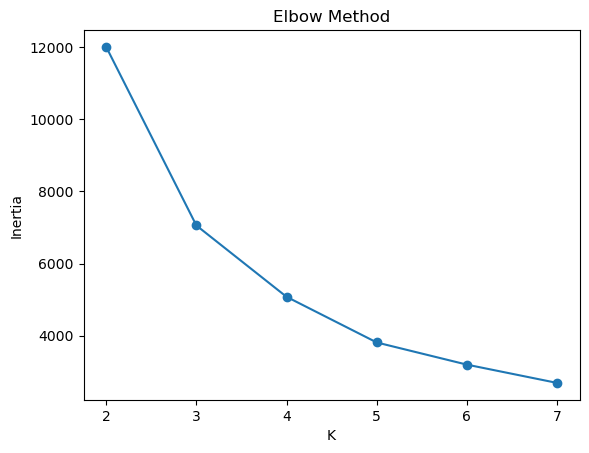

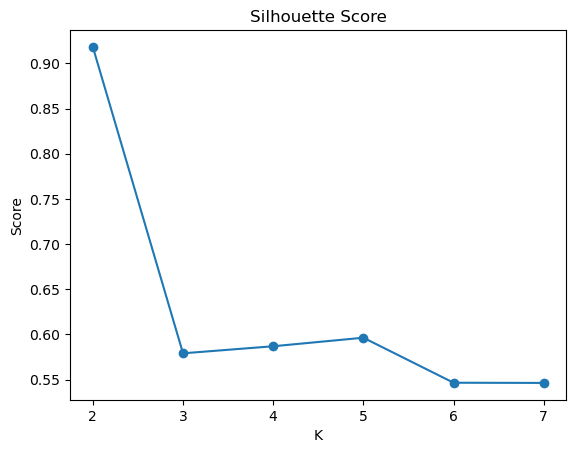

In [15]:
inertia = []
scores = []

for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    inertia.append(model.inertia_)
    scores.append(silhouette_score(X, labels))

plt.plot(range(2, 8), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.show()

plt.plot(range(2, 8), scores, marker="o")
plt.title("Silhouette Score")
plt.xlabel("K")
plt.ylabel("Score")
plt.show()

In [16]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["KMeans"] = kmeans.fit_predict(X)

## 5. DBSCAN

In [17]:
dbscan = DBSCAN(eps=0.8, min_samples=8)
rfm["DBSCAN"] = dbscan.fit_predict(X)
print(rfm["DBSCAN"].value_counts())  # -1 means noise

DBSCAN
 0    5805
-1      55
Name: count, dtype: int64


## 6. PCA visualization

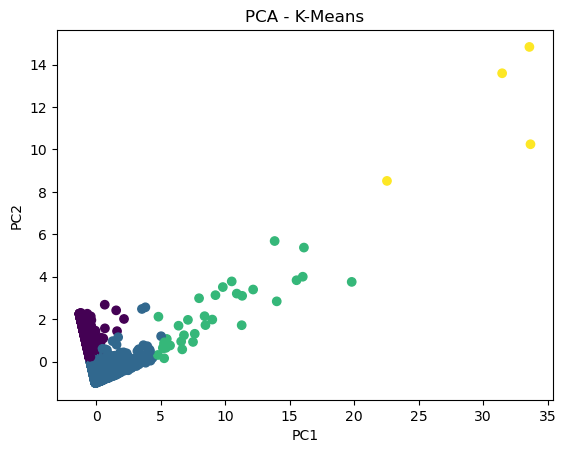

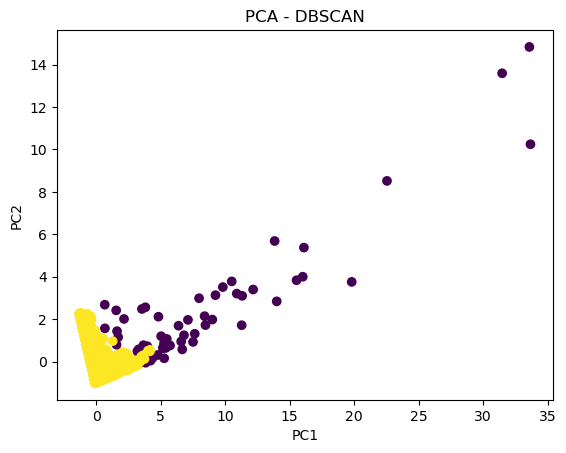

Variance explained: [0.57805721 0.30513509]


In [18]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=rfm["KMeans"])
plt.title("PCA - K-Means")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=rfm["DBSCAN"])
plt.title("PCA - DBSCAN")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

print("Variance explained:", pca.explained_variance_ratio_)

## 7. t-SNE visualization

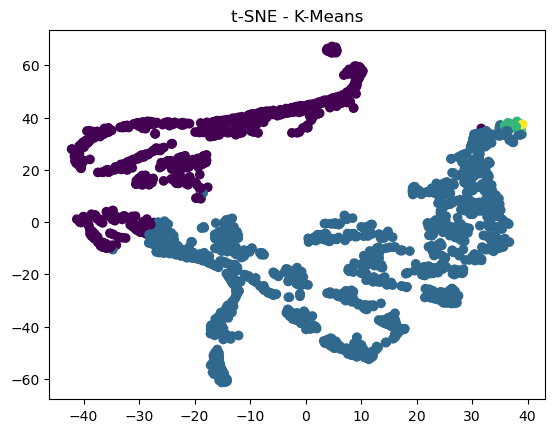

In [19]:
# Use a sample so t-SNE runs faster
n = min(2000, len(X))
X_sample = X[:n]
tsne = TSNE(n_components=2, random_state=42, init="pca", learning_rate="auto")
X_tsne = tsne.fit_transform(X_sample)

plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=rfm["KMeans"].iloc[:n])
plt.title("t-SNE - K-Means")
plt.show()

## 8. View segments and save

In [20]:
print(rfm.groupby("KMeans")[["Recency", "Frequency", "Monetary"]].mean())
rfm.to_csv("customer_segmentation_results.csv", index=False)
print("Saved customer_segmentation_results.csv")

           Recency   Frequency       Monetary
KMeans                                       
0       459.238238    2.196196     740.280872
1        67.798379    7.228295    2917.560390
2        26.823529  105.617647   77533.422706
3         6.750000  209.250000  421233.115000
Saved customer_segmentation_results.csv


## Conclusion

- RFM describes how recently, how often and how much customers purchase.
- K-Means groups customers into a chosen number of clusters.
- Elbow and silhouette help assess K.
- DBSCAN finds dense groups and marks noise as `-1`.
- PCA reduces features to 2D; t-SNE gives another 2D visualization.